# Module 7 Lab 2 — What Drives a Restaurant's Overall Rating?
**Problem 7.1** · Multi-feature linear regression

**Question:** Which of *food*, *ambience*, and *service* has the biggest effect on a restaurant's overall rating, and what should a struggling owner fix first?

**Name:** Roey Kadur

Repo URL: https://github.com/roee0910/cs82a-portfolio.git

## Step 1 — Load the data
We import the tools and read `ratings.tsv`. The file is tab-separated, so we use `sep="\t"`.

In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

df = pd.read_csv("ratings.tsv", sep="\t")
df

,restaurant,food,ambience,service,rating
0,1,85,82,89,78
1,2,80,90,80,85
2,3,83,86,83,85
3,4,70,96,75,72
4,5,68,80,78,75
5,6,65,70,56,54
6,7,64,68,61,62
7,8,72,95,72,73
8,9,69,70,78,70
9,10,75,80,75,77


## Step 2 — Check the data
We check the size, missing values, and basic statistics. All scores are on a similar 0–100 scale, so the slopes can be compared fairly.

In [2]:
print("Shape (rows, columns):", df.shape)
print("Missing values per column:")
print(df.isna().sum())

Shape (rows, columns): (15, 5)
Missing values per column:
restaurant    0
food          0
ambience      0
service       0
rating        0
dtype: int64


In [3]:
df[["food", "ambience", "service", "rating"]].describe().round(2)

,food,ambience,service,rating
count,15.00,15.00,15.00,15.00
mean,73.13,81.73,75.13,73.07
std,6.56,9.79,8.07,8.32
min,64.00,68.00,56.00,54.00
25%,68.50,71.00,73.50,70.50
50%,72.00,82.00,78.00,74.00
75%,77.50,90.00,78.00,77.50
max,85.00,96.00,89.00,85.00


## Step 3 — Look at the relationships
The correlation of each factor with `rating` gives a first hint. A higher number means the two move together more strongly.

In [4]:
df[["food", "ambience", "service", "rating"]].corr().round(3)["rating"].drop("rating").sort_values(ascending=False)

food        0.839
service     0.797
ambience    0.372
Name: rating, dtype: float64

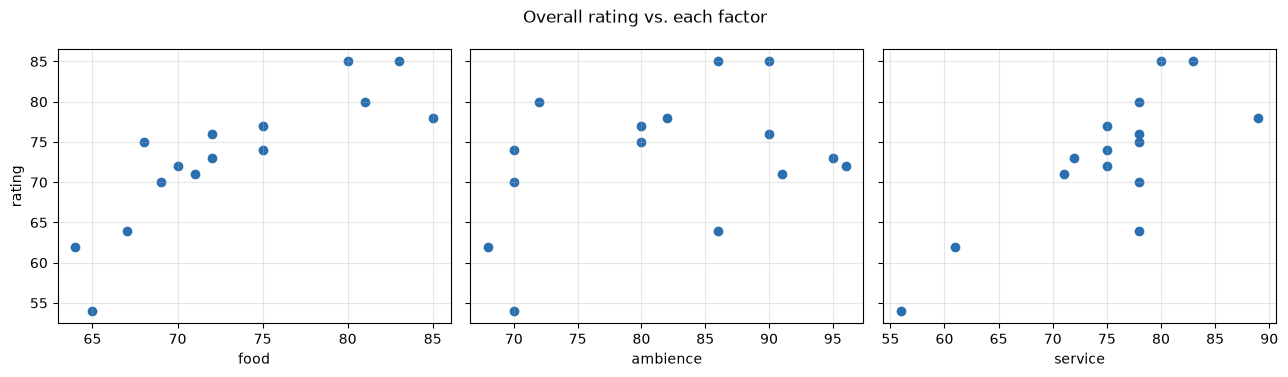

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, col in zip(axes, ["food", "ambience", "service"]):
    ax.scatter(df[col], df["rating"], color="#2a6fb0")
    ax.set_xlabel(col)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("rating")
fig.suptitle("Overall rating vs. each factor")
plt.tight_layout()
plt.show()

## Step 4 — Build X and y
`X` holds the three features and `y` is the target (`rating`). The column order matters, because `model.coef_` returns one slope per column **in this same order**.

In [6]:
features = ["ambience", "food", "service"]
X = df[features]
y = df["rating"]
print("Feature order:", list(X.columns))
print("X shape:", X.shape, "| y shape:", y.shape)

Feature order: ['ambience', 'food', 'service']
X shape: (15, 3) | y shape: (15,)


## Step 5 — Fit the model
We fit `LinearRegression` on all 15 restaurants. With so few rows, using all of them gives the most stable coefficients. The model is:

`rating = intercept + b1·ambience + b2·food + b3·service`

In [7]:
model = LinearRegression()
model.fit(X, y)

print("Intercept:", round(model.intercept_, 4))
print("Raw coef_ array:", model.coef_)

Intercept: -15.8713
Raw coef_ array: [0.13376097 0.7337757  0.32398064]


## Step 6 — Match each coefficient to its feature and rank them
We pair every number in `coef_` with its column name (same position), then sort from largest to smallest.

In [8]:
coef_table = (
    pd.DataFrame({"feature": features, "coefficient": model.coef_})
    .sort_values("coefficient", ascending=False)
    .reset_index(drop=True)
)
coef_table.index = coef_table.index + 1
coef_table.index.name = "rank"
coef_table["coefficient"] = coef_table["coefficient"].round(4)
coef_table

,feature,coefficient
rank,,
1,food,0.7338
2,service,0.3240
3,ambience,0.1338


**How to read a coefficient:** it is the expected change in overall rating for **+1 point** in that factor, while the other two factors stay the same.

In [9]:
for rank, row in coef_table.iterrows():
    print(f"{rank}. {row['feature']:<9} +1 point -> rating changes by {row['coefficient']:+.3f}")

1. food      +1 point -> rating changes by +0.734
2. service   +1 point -> rating changes by +0.324
3. ambience  +1 point -> rating changes by +0.134


## Step 7 — Evaluate the model
R² tells us how much of the variation in `rating` the three factors explain together. We also check the errors (RMSE, MAE) in rating points.

In [10]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pred = model.predict(X)
print("R^2 :", round(r2_score(y, pred), 4))
print("RMSE:", round(float(np.sqrt(mean_squared_error(y, pred))), 3), "rating points")
print("MAE :", round(mean_absolute_error(y, pred), 3), "rating points")

R^2 : 0.7943
RMSE: 3.645 rating points
MAE : 2.764 rating points


## Step 8 — Verify the result
We check the answer in two independent ways:

1. Solve the same regression with plain NumPy least squares. The numbers must match.
2. Standardize the features (same scale for all) and refit. If the ranking stays the same, the conclusion does not depend on the units.

In [11]:
# Check 1: NumPy least squares
A = np.column_stack([np.ones(len(X)), X.values])
beta, *_ = np.linalg.lstsq(A, y.values, rcond=None)
check = pd.DataFrame({"sklearn": [model.intercept_, *model.coef_],
                      "numpy": beta},
                     index=["intercept", *features]).round(4)
print(check)
print("Match:", np.allclose(check["sklearn"], check["numpy"]))

           sklearn    numpy
intercept -15.8713 -15.8713
ambience    0.1338   0.1338
food        0.7338   0.7338
service     0.3240   0.3240
Match: True


In [12]:
# Check 2: standardized coefficients (z-scores)
Z = (X - X.mean()) / X.std()
z_model = LinearRegression().fit(Z, (y - y.mean()) / y.std())
std_table = (pd.Series(z_model.coef_, index=features)
             .sort_values(ascending=False).round(4).rename("standardized coef"))
std_table

food        0.5783
service     0.3143
ambience    0.1574
Name: standardized coef, dtype: float64

## Step 9 — Visualize the ranking

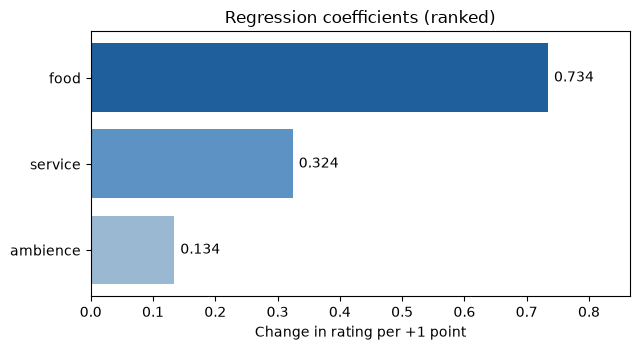

In [13]:
ordered = coef_table.set_index("feature")["coefficient"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.barh(ordered.index[::-1], ordered.values[::-1], color=["#9bb8d3", "#5c93c4", "#1f5f9c"])
for b, v in zip(bars, ordered.values[::-1]):
    ax.text(v + 0.01, b.get_y() + b.get_height()/2, f"{v:.3f}", va="center")
ax.set_xlabel("Change in rating per +1 point")
ax.set_title("Regression coefficients (ranked)")
ax.set_xlim(0, ordered.max() * 1.18)
plt.tight_layout()
plt.show()

## Step 10 — Final answer
**Fitted model:** `rating = -15.871 + 0.1338·ambience + 0.7338·food + 0.3240·service`  (R² = 0.794)

**Ranked coefficients** (change in rating per +1 point)

1. **food**: 0.7338
2. **service**: 0.3240
3. **ambience**: 0.1338

**Recommendation:** A struggling restaurant should fix **food first**. Each extra point of food quality adds about 0.73 points to the overall rating, which is more than twice the effect of service (0.32) and about 5.5 times the effect of ambience (0.13). Fix service second, and leave ambience for last.

*Note:* with only 15 restaurants, these are estimates, and the results show association, not proof of cause. The ranking is the same after standardizing the features (Step 8).